First: What is our problem?


We have information about different houses, and we want to build a Machine Learning model that can predict the price of a house.

This is a Supervised Learning problem because our dataset already contains the correct answer: Price_house.

The model will learn from existing examples:

House information → Known house price

and later:

New house information → Predicted house price

# Applying Linear Regression to Our Dataset

In this practical, we are going to build a **Machine Learning model to predict house prices** using our dataset.

Our dataset contains information about different houses, such as:

* Taxi distance

* Market distance

* Hospital distance

* Carpet area

* Built-up area

* Parking type

* City type

* Rainfall

The value that we want our model to predict is:

**`Price_house`**

Because `Price_house` is a **continuous numerical value**, this is a **Regression problem**.

For this problem, we will apply **Linear Regression**.

More specifically, because we are using multiple input features to predict one target, we are applying **Multiple Linear Regression**.

Our goal is:

**House Information → Linear Regression Model → Predicted House Price**

We will follow these steps:

1. Load the dataset

2. Understand the dataset

3. Handle missing values

4. Separate features and target

5. Identify numerical and categorical features

6. Encode categorical features

7. Split the dataset into training and testing data

8. Create the Linear Regression model

9. Train the model

10. Make predictions

11. Evaluate the model

12. Visualize the results

13. Understand how well our model performs


By the end of this practical, students will understand how a real-world dataset is converted into a **trained Machine Learning model** that can predict house prices.


Problem: Predict Price_house

Type: Supervised Learning → Regression

Algorithm: Multiple Linear Regression

Target: Price_house

Features: 8 input columns

| Column          | What it means                                        | Type        | ML Role    |
| --------------- | ---------------------------------------------------- | ----------- | ---------- |
| `Taxi_dist`     | Distance from the house to a taxi/transport facility | Numerical   | Feature    |
| `Market_dist`   | Distance from the house to a market                  | Numerical   | Feature    |
| `Hospital_dist` | Distance from the house to a hospital                | Numerical   | Feature    |
| `Carpet_area`   | Carpet/usable area of the house                      | Numerical   | Feature    |
| `Builtup_area`  | Built-up area of the house                           | Numerical   | Feature    |
| `Parking_type`  | Type/status of parking                               | Categorical | Feature    |
| `City_type`     | Category/type of city                                | Categorical | Feature    |
| `Rainfall`      | Rainfall amount/level                                | Numerical   | Feature    |
| `Price_house`   | Price of the house                                   | Numerical   | **Target** |



In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv(r"E:\states\my notes\3rd week\Data.csv")


In [3]:
# Display first 5 rows
print(df.head())

# Display dataset information
print(df.info())

# Check missing values
print(df.isnull().sum())

# Check number of rows and columns
print(df.shape)

   Taxi_dist  Market_dist  Hospital_dist  Carpet_area  Builtup_area  \
0     9796.0       5250.0        10703.0       1659.0        1961.0   
1     8294.0       8186.0        12694.0       1461.0        1752.0   
2    11001.0      14399.0        16991.0       1340.0        1609.0   
3     8301.0      11188.0        12289.0       1451.0        1748.0   
4    10510.0      12629.0        13921.0       1770.0        2111.0   

   Parking_type City_type  Rainfall  Price_house  
0          Open     CAT B       530      6649000  
1  Not Provided     CAT B       210      3982000  
2  Not Provided     CAT A       720      5401000  
3       Covered     CAT B       620      5373000  
4  Not Provided     CAT B       450      4662000  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 932 entries, 0 to 931
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Taxi_dist      919 non-null    float64
 1   Market_dist    919 non-nul

In [4]:
print(df.shape)

(932, 9)


In [5]:
print(df.columns)

Index(['Taxi_dist', 'Market_dist', 'Hospital_dist', 'Carpet_area',
       'Builtup_area', 'Parking_type', 'City_type', 'Rainfall', 'Price_house'],
      dtype='object')


In [6]:
print(df.dtypes)

Taxi_dist        float64
Market_dist      float64
Hospital_dist    float64
Carpet_area      float64
Builtup_area     float64
Parking_type      object
City_type         object
Rainfall           int64
Price_house        int64
dtype: object


In [7]:
df.describe()

,Taxi_dist,Market_dist,Hospital_dist,Carpet_area,Builtup_area,Rainfall,Price_house
count,919.000000,919.000000,931.000000,924.000000,917.000000,932.000000,9.320000e+02
mean,8229.727965,11018.752992,13072.092374,1511.862554,1794.924755,785.579399,6.084695e+06
std,2561.985008,2543.920590,2586.456161,790.969660,468.159457,265.546853,5.025364e+06
min,146.000000,1666.000000,3227.000000,775.000000,932.000000,-110.000000,3.000000e+04
25%,6476.000000,9354.500000,11301.500000,1318.000000,1583.000000,600.000000,4.658000e+06
50%,8230.000000,11161.000000,13163.000000,1480.500000,1774.000000,780.000000,5.866000e+06
75%,9937.000000,12670.500000,14817.000000,1655.000000,1982.000000,970.000000,7.187250e+06
max,20662.000000,20945.000000,23294.000000,24300.000000,12730.000000,1560.000000,1.500000e+08


In [8]:
print(df.isnull().sum())

Taxi_dist        13
Market_dist      13
Hospital_dist     1
Carpet_area       8
Builtup_area     15
Parking_type      0
City_type         0
Rainfall          0
Price_house       0
dtype: int64


Handling Missing Values

Your dataset has:

Taxi_dist → 13 missing

Market_dist → 13 missing

Hospital_dist → 1 missing

Carpet_area → 8 missing

Builtup_area → 15 missing

Total = 50 missing values.

Method 1: Remove Missing Values

In [12]:
df.isnull().sum()

Taxi_dist        13
Market_dist      13
Hospital_dist     1
Carpet_area       8
Builtup_area     15
Parking_type      0
City_type         0
Rainfall          0
Price_house       0
dtype: int64

Step 2 — Remove rows containing missing values

In [13]:
df_clean = df.dropna()

In [14]:
print(df_clean.isnull().sum())

Taxi_dist        0
Market_dist      0
Hospital_dist    0
Carpet_area      0
Builtup_area     0
Parking_type     0
City_type        0
Rainfall         0
Price_house      0
dtype: int64


In [15]:
print("Original shape:", df.shape)
print("New shape:", df_clean.shape)

Original shape: (932, 9)
New shape: (898, 9)


In [16]:
X = df_clean.drop("Price_house", axis=1)
y = df_clean["Price_house"]

In [17]:
print(X.head())
print(y.head())

   Taxi_dist  Market_dist  Hospital_dist  Carpet_area  Builtup_area  \
0     9796.0       5250.0        10703.0       1659.0        1961.0   
1     8294.0       8186.0        12694.0       1461.0        1752.0   
2    11001.0      14399.0        16991.0       1340.0        1609.0   
3     8301.0      11188.0        12289.0       1451.0        1748.0   
4    10510.0      12629.0        13921.0       1770.0        2111.0   

   Parking_type City_type  Rainfall  
0          Open     CAT B       530  
1  Not Provided     CAT B       210  
2  Not Provided     CAT A       720  
3       Covered     CAT B       620  
4  Not Provided     CAT B       450  
0    6649000
1    3982000
2    5401000
3    5373000
4    4662000
Name: Price_house, dtype: int64


dentify numerical and categorical columns

Your dataset contains both.

Numerical

In [22]:
numerical_features = [
    "Taxi_dist",
    "Market_dist",
    "Hospital_dist",
    "Carpet_area",
    "Builtup_area",
    "Rainfall"
]

In [23]:
categorical_features = [
    "Parking_type",
    "City_type"
]

Convert categorical data to numbers

In [18]:
from sklearn.preprocessing import OneHotEncoder

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

Categorical columns

       ↓

OneHotEncoder

       ↓

Numbers


Numerical columns

       ↓
       
Keep as they are

Split the dataset

Now we divide the 898 rows into training and testing data.

We'll use:

80% training + 20% testing

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [27]:
from sklearn.linear_model import LinearRegression

In [28]:
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

In [29]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Parking_type',
                                                   'City_type'])])),
                ('regression', LinearRegression())])

In [30]:
y_pred = model.predict(X_test)

In [31]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0       5750000     4.999176e+06
1       4935000     4.894344e+06
2       3523000     4.135987e+06
3       5929000     7.221946e+06
4       4548000     5.252408e+06
5       4855000     5.551149e+06
6       3194000     4.884284e+06
7       4558000     5.686800e+06
8       3783000     4.485208e+06
9       6094000     5.478976e+06


In [32]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 997902.22936909
MSE : 1697676576119.991
RMSE: 1302949.1840129418
R²  : 0.4472403231794013


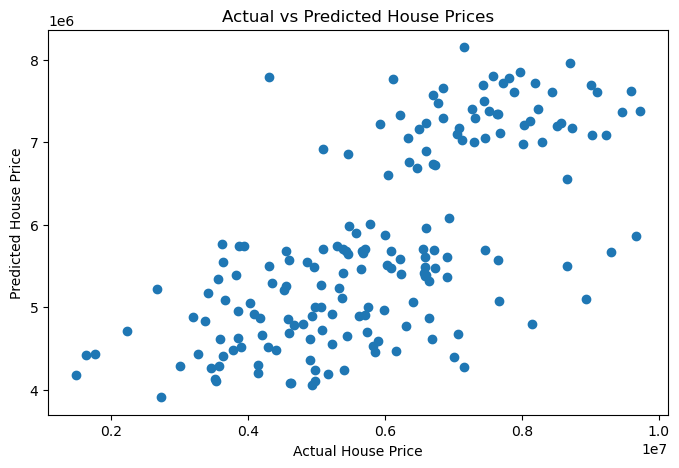

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [34]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [35]:
df = pd.read_csv(r"E:\states\my notes\3rd week\Data.csv")

print("Original dataset:", df.shape)

Original dataset: (932, 9)


In [36]:
# --------------------------------------------------
# 3. Separate Features and Target
# --------------------------------------------------

X = df_clean.drop("Price_house", axis=1)

y = df_clean["Price_house"]

In [37]:
# --------------------------------------------------
# 4. Define numerical and categorical features
# --------------------------------------------------

numerical_features = [
    "Taxi_dist",
    "Market_dist",
    "Hospital_dist",
    "Carpet_area",
    "Builtup_area",
    "Rainfall"
]

In [38]:
categorical_features = [
    "Parking_type",
    "City_type"
]


In [39]:
# 5. Encode categorical features
# --------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)



In [40]:
# --------------------------------------------------
# 6. Create Linear Regression model
# --------------------------------------------------

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])


In [41]:
# --------------------------------------------------
# 7. Split data
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [42]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)



Training data: (718, 8)
Testing data: (180, 8)


In [44]:
#--------------------------------------------------
# 8. Train the model
# --------------------------------------------------

model.fit(X_train, y_train)

print("Model trained successfully!")



Model trained successfully!


In [45]:
# --------------------------------------------------
# 9. Make predictions
# --------------------------------------------------

y_pred = model.predict(X_test)

In [46]:
# --------------------------------------------------
# 10. Evaluate model
# --------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred)


print("\nModel Performance")
print("-------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)


Model Performance
-------------------------
MAE : 997902.22936909
MSE : 1697676576119.991
RMSE: 1302949.1840129418
R²  : 0.4472403231794013


Original dataset: (932, 9)
Clean dataset: (898, 9)

Training data: (...)
Testing data: (...)

Model trained successfully!

Model Performance
-------------------------
MAE : ...

MSE : ...

RMSE: ...

R²  : ...

DATA

 ↓

Missing Values

 ↓

Clean Data

 ↓
 
 
 ↓

Numerical / Categorical

 ↓

Encoding

 ↓

Train/Test Split

 ↓

Linear Regression

 ↓

Training

 ↓

Prediction

 ↓

Evaluation
